# Load required libraries for data management and plotting

In [1]:
import pandas as pd
import ast
import seaborn as sns
import numpy as np
import matplotlib.pyplot as plt
import tqdm
import ast
import collections
import os
import cv2

# Define data handling functions for loading the result data

In [2]:
df_synthetic = pd.read_csv("composite_videos/Synthetic-Video-Mapping-Groundtruth.csv")
synth_to_truth = {row.Synthetic_Video: ast.literal_eval(row.Original_Clips.replace("'",'"')) for id, row in df_synthetic.iterrows()}
all_clips = sorted(set([v.split('.')[0] for vids in synth_to_truth.values() for v in vids]))

def load_process_data(model, rep_frame_threshold, match_frame_threshold, filter_to_threshold):
	"""Load the necessary results file filtered to a given threshold and preprocess to the correct column format."""

	## Load the data.
	df = pd.read_csv(f"Results/Results_of_Comparison_metrics-Pixabay-{model}-{rep_frame_threshold}-{match_frame_threshold}-{filter_to_threshold}.csv")
	df['True Positives Num'] = df['True Positives'].values
	df['Ground Truth'] = [[vid.replace('.mp4','') for vid in synth_to_truth[row['Filename'].replace('matches_','').split('.')[0].replace(f'{model}_','')]] for id,row in df.iterrows()]
	df['True Positives'] = [row['Ground Truth'] if type(row['False Negatives']) != str else ','.join([f for f in row['Ground Truth'] if f not in row['False Negatives']]) for id, row in df.iterrows()]
	df['True Negatives Num'] = [125-row['True Positives Num']-row['False Positives Num']-row['False Negatives Num'] for id,row in df.iterrows()]

	df['Precision'] = df['True Positives Num']/(df['True Positives Num']+df['False Positives Num'])
	df['Recall'] = df['True Positives Num']/(df['True Positives Num']+df['False Negatives Num'])

	df['Specificity'] = df['True Negatives Num']/(df['True Negatives Num'] + df['False Positives Num'])
	df['Sensitivity'] = df['True Negatives Num']/(df['True Negatives Num'] + df['True Positives Num'])
	df['Balanced Accuracy'] = (df['Sensitivity']+df['Recall'])/2

	df['Precision'] = df['Precision'].fillna(0)
	df['Recall'] = df['Recall'].fillna(0)
	df["False Positive Rate"] = df["False Positives Num"]/(df["False Positives Num"] + df["True Negatives Num"])
	df["False Negative Rate"] = df["False Negatives Num"]/(df["False Negatives Num"] + df["True Positives Num"])

	## Format the data for efficient accuracy comparison.
	df['File ID'] = [int(f.split('_')[-1].split('.')[0]) for f in df.Filename]
	df = df.sort_values(by='File ID').reset_index()

	return df

def make_fpp_vs_fnp_data(threshold,model):
	df = load_process_data(model,threshold,threshold,threshold)
	false_negs = [n for n in df['False Negatives'] if type(n) == str]
	false_negs = [n for nums in false_negs for n in nums.split(',')]
	
	false_pos = [n for n in df['False Positives'] if type(n) == str]
	false_pos = [n for nums in false_pos for n in nums.split(',')]

	fn_count = collections.Counter(false_negs)
	fp_count = collections.Counter(false_pos)
	clip_stats = {}
	clips = []
	for id, row in df.iterrows():
		for clip in row['Ground Truth']:
			if clip_stats.get(clip) == None:
				clip_stats[clip] = []
				clips.append(clip)
			if clip in row['True Positives']:
				clip_stats[clip].append('T')
			else:
				clip_stats[clip].append('F')
	clips = sorted(list(set(clips)))
	fp_prop = {c:np.round(fp_count.get(c,0)/len(clip_stats[c]),2) for c in clips}
	fn_prop = {c:np.round(fn_count.get(c,0)/len(clip_stats[c]),2) for c in clips}

	data_prop = list(zip(clips,[fp_prop[c] for c in clips],[fn_prop[c] for c in clips],[model_label_map[model]]*len(clips),[threshold]*len(clips)))
	df_prop = pd.DataFrame(data=data_prop,columns=["Clips","False Positive Proportion","False Negative Proportion","Model","Threshold"])
	return df_prop


# Model and threshold definitions reused throughout

In [3]:
thresholds = [
	0.1,
	0.2,
	0.3,
	0.4,
	0.5,
	0.6000000000000001,
	0.7000000000000002,
	0.8000000000000003,
	0.9000000000000001
]

models = ["clip-vit-base-patch16","densenet121","resnet50"]
model_label_map = {"densenet121":"DenseNet-121","resnet50":"ResNet-50","clip-vit-base-patch16":"CLIP-ViT-B-16"}

# Helper functions for calculating recall@k. Loads the model evaluation results and calculates the relevant recall@k statistics

In [4]:
def calculate_prop_recall_at_k(k,df,threshold,truth,unique=True):
	""" Given a dataframe of video labels and similarities, calculate the average recall at k, i.e. how many of the ground truth videos are included? """

	prop_recalls = []
	for composite in range(1,126):
		trim = df[df.comp_vid_id == composite]
		
		## Get the top k matches for each video. Currently this accounts for duplicate frames so will not necessarily be unique original videos.
		trim = trim.sort_values(by='sim')

		## Remove any that are beyond the threshold (in such cases there will be fewer than k original videos matched).
		trim = trim[trim.sim <= threshold]

		## Now extract the first k unique video ids (alternatively adjust this to allow for multiple frame matches).
		if unique:
			matches = []
			for v in trim.orig_vid:
				if v not in matches and len(matches) < k:
					matches.append(v)
		else:
			matches = trim.orig_vid.iloc[:k]

		## Record the proportional size of the intersection. This value should range between 0 and 6.
		prop_recalls.append(len(set(matches).intersection(truth[composite])))
	
	## Return the mean and standard deviation for error bar purposes over all composites.
	return prop_recalls

def count_matches(df,thresh):
	""" Count the number of original clips that are within the required similarity range of each composite. """

	match_counts = []
	for composite in range(1,126):
		trim = df[df.comp_vid_id == composite]

		## Remove any that are beyond the threshold (in such cases there will be fewer than k original videos matched).
		trim = trim[trim.sim <= thresh]

		match_counts.append(len(trim.orig_vid.unique()))
	
	## Return the mean and standard deviation for visualisation purposes.
	return np.mean(match_counts), np.std(match_counts)


df_truth = pd.read_csv("composite_videos/Synthetic-Video-Mapping-Groundtruth.csv")
included_clips = {}
for id, row in df_truth.iterrows():
	included_clips[int(id+1)] = set(ast.literal_eval(row.Original_Clips))

data = []
data_matches = []
for model in models:
	for threshold in thresholds:
		data_folder = f"Results/evaluation_{model}_{threshold}_{threshold}/Results"
		comp_vid_id = []
		comp_frame_id = []
		orig_vid_id = []
		orig_frame_id = []
		sim = []
		groundtruth = []
		
		for i in tqdm.tqdm(range(1,125+1)):
			try:
				df = pd.read_csv(f'{data_folder}/matches_{model}_Test_video_{i}.csv')
				
				for id, row in df.iterrows():
					comp_vid_id.append(int(i))
					comp_frame_id.append(int(row.frame_id))
					orig_vid_id.append(row.mapped_video_name.strip())
					orig_frame_id.append(int(row.mapped_video_frame))
					sim.append(float(row.similarity))
					if row.mapped_video_name.strip() in included_clips[int(i)]:
						groundtruth.append(1)
					else:
						groundtruth.append(0)
			except FileNotFoundError:
				print(f'Missing file for i={i}')

		df_match = pd.DataFrame({'comp_vid_id':comp_vid_id,'comp_frame_id':comp_frame_id,'orig_vid':orig_vid_id,'orig_frame_id':orig_frame_id,'sim':sim,'groundtruth':groundtruth})
		distribution_1 = calculate_prop_recall_at_k(1,df_match,threshold,included_clips)
		distribution_6 = calculate_prop_recall_at_k(6,df_match,threshold,included_clips)
		distribution_12 = calculate_prop_recall_at_k(12,df_match,threshold,included_clips)
		mean_matches,matches_std = count_matches(df_match,threshold)
		data.extend(zip(distribution_1 + distribution_6+ distribution_12, [1]*len(distribution_1)+[6]*len(distribution_1)+[12]*len(distribution_1), [model_label_map[model]]*len(distribution_1)*3, [np.round(threshold,2)]*len(distribution_1)*3))
		data_matches.extend(zip([mean_matches],[matches_std], [model_label_map[model]], [np.round(threshold,2)]))


df_top_k = pd.DataFrame(data,columns=["Top K","k","Model","Threshold"])
df_matches = pd.DataFrame(data_matches,columns=["mean_matches","matches_std","Model","Threshold"])


100%|████████████████████████████████████████████████████████████████████████████████████████| 125/125 [00:03<00:00, 34.90it/s]


# Plot precision, recall and balanced accuracy - Fig 4 a,b,c

The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.


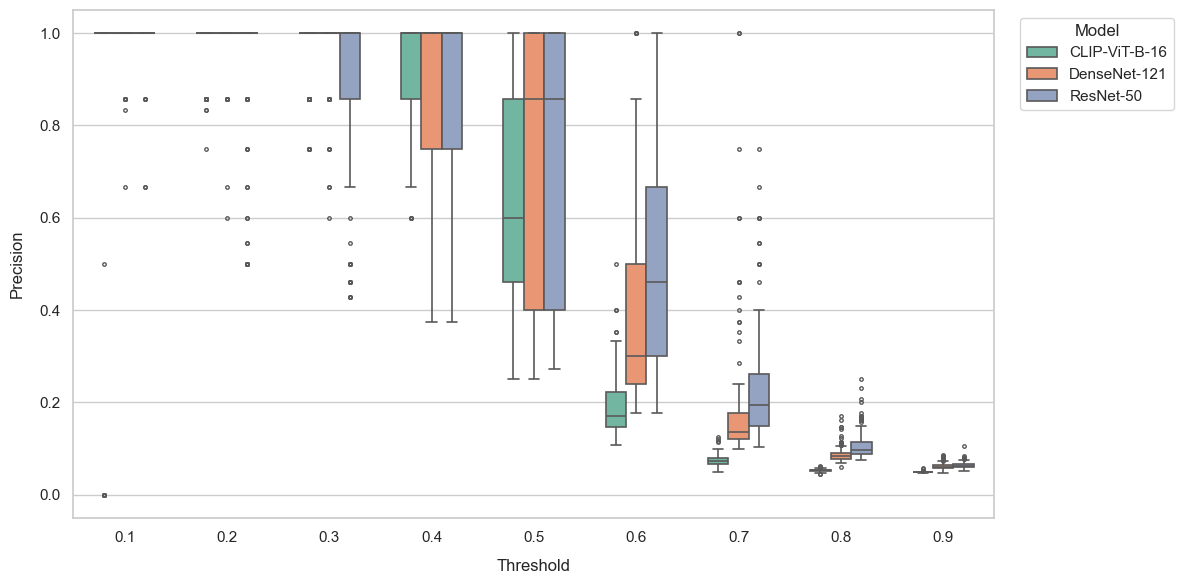

In [5]:
all_dfs = []
for model in models:
    for threshold in thresholds:
        df = load_process_data(model, threshold, threshold, threshold)
        df["Threshold"] = np.round(threshold, 2)
        df["Model"] = model_label_map[model]
        all_dfs.append(df)
        
df_master = pd.concat(all_dfs, ignore_index=True)

sns.set_theme(style="whitegrid")
plt.figure(figsize=(12, 6))

ax = sns.boxplot(
    data=df_master, 
    x="Threshold", 
    y="Precision", 
    hue="Model",
    palette="Set2",       
    width=0.6,            
    fliersize=2.5,        
    linewidth=1.2
)

plt.xlabel("Threshold", fontsize=12, labelpad=10)
plt.ylabel("Precision", fontsize=12, labelpad=10)

plt.legend(title="Model", bbox_to_anchor=(1.02, 1), loc='upper left', frameon=True)

plt.tight_layout()
plt.savefig('figs/fig_4a.eps',bbox_inches='tight')
plt.show()

The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.


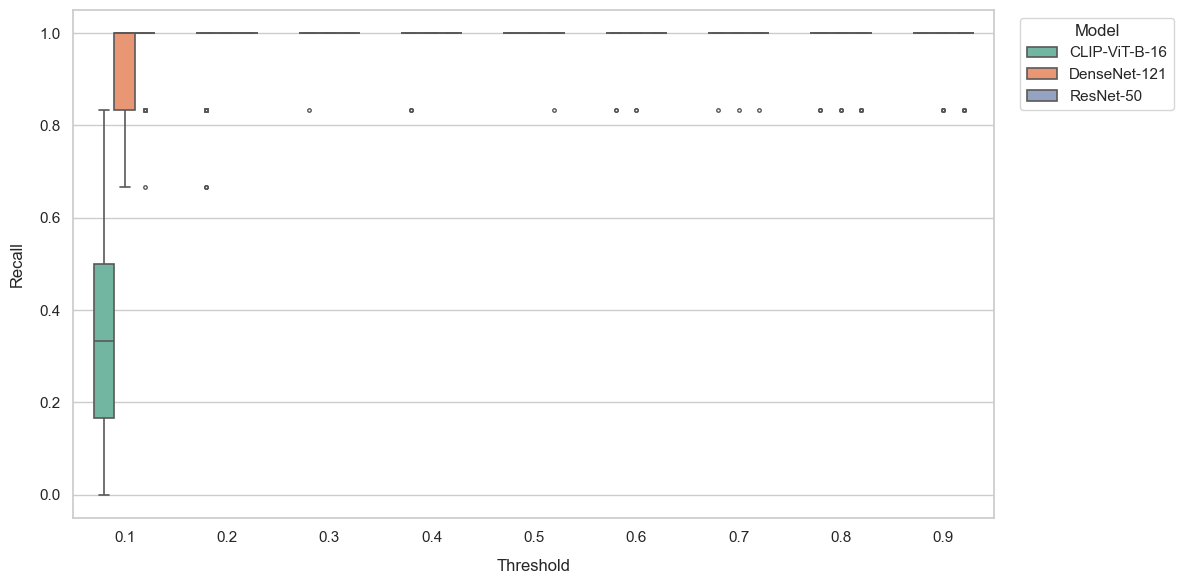

In [6]:
sns.set_theme(style="whitegrid")
plt.figure(figsize=(12, 6))

ax = sns.boxplot(
    data=df_master, 
    x="Threshold", 
    y="Recall", 
    hue="Model",
    palette="Set2",       
    width=0.6,            
    fliersize=2.5,        
    linewidth=1.2
)

plt.xlabel("Threshold", fontsize=12, labelpad=10)
plt.ylabel("Recall", fontsize=12, labelpad=10)

plt.legend(title="Model", bbox_to_anchor=(1.02, 1), loc='upper left', frameon=True)

plt.tight_layout()
plt.savefig('figs/fig_4b.eps',bbox_inches='tight')
plt.show()

The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.


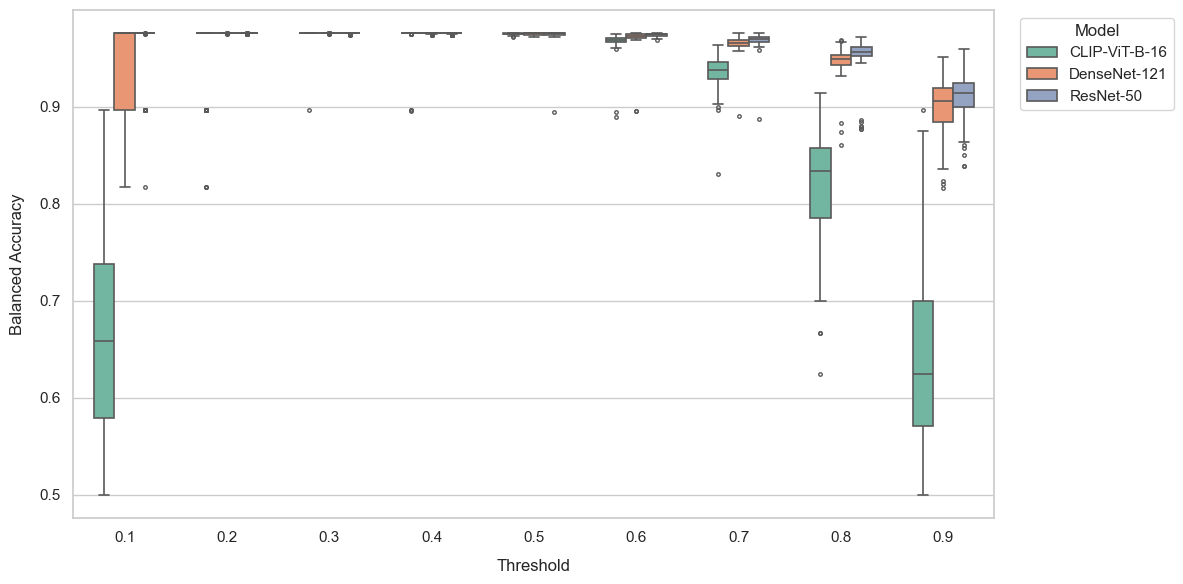

In [7]:
sns.set_theme(style="whitegrid")
plt.figure(figsize=(12, 6))

ax = sns.boxplot(
    data=df_master, 
    x="Threshold", 
    y="Balanced Accuracy", 
    hue="Model",
    palette="Set2",       
    width=0.6,            
    fliersize=2.5,        
    linewidth=1.2
)

plt.xlabel("Threshold", fontsize=12, labelpad=10)
plt.ylabel("Balanced Accuracy", fontsize=12, labelpad=10)

plt.legend(title="Model", bbox_to_anchor=(1.02, 1), loc='upper left', frameon=True)

plt.tight_layout()
plt.savefig('figs/fig_4c.eps',bbox_inches='tight')
plt.show()

# Plot the proportions of false positives and false negatives for each clip, normalised by the number of composites they appear in (Fig. 5)

<Figure size 1200x600 with 0 Axes>

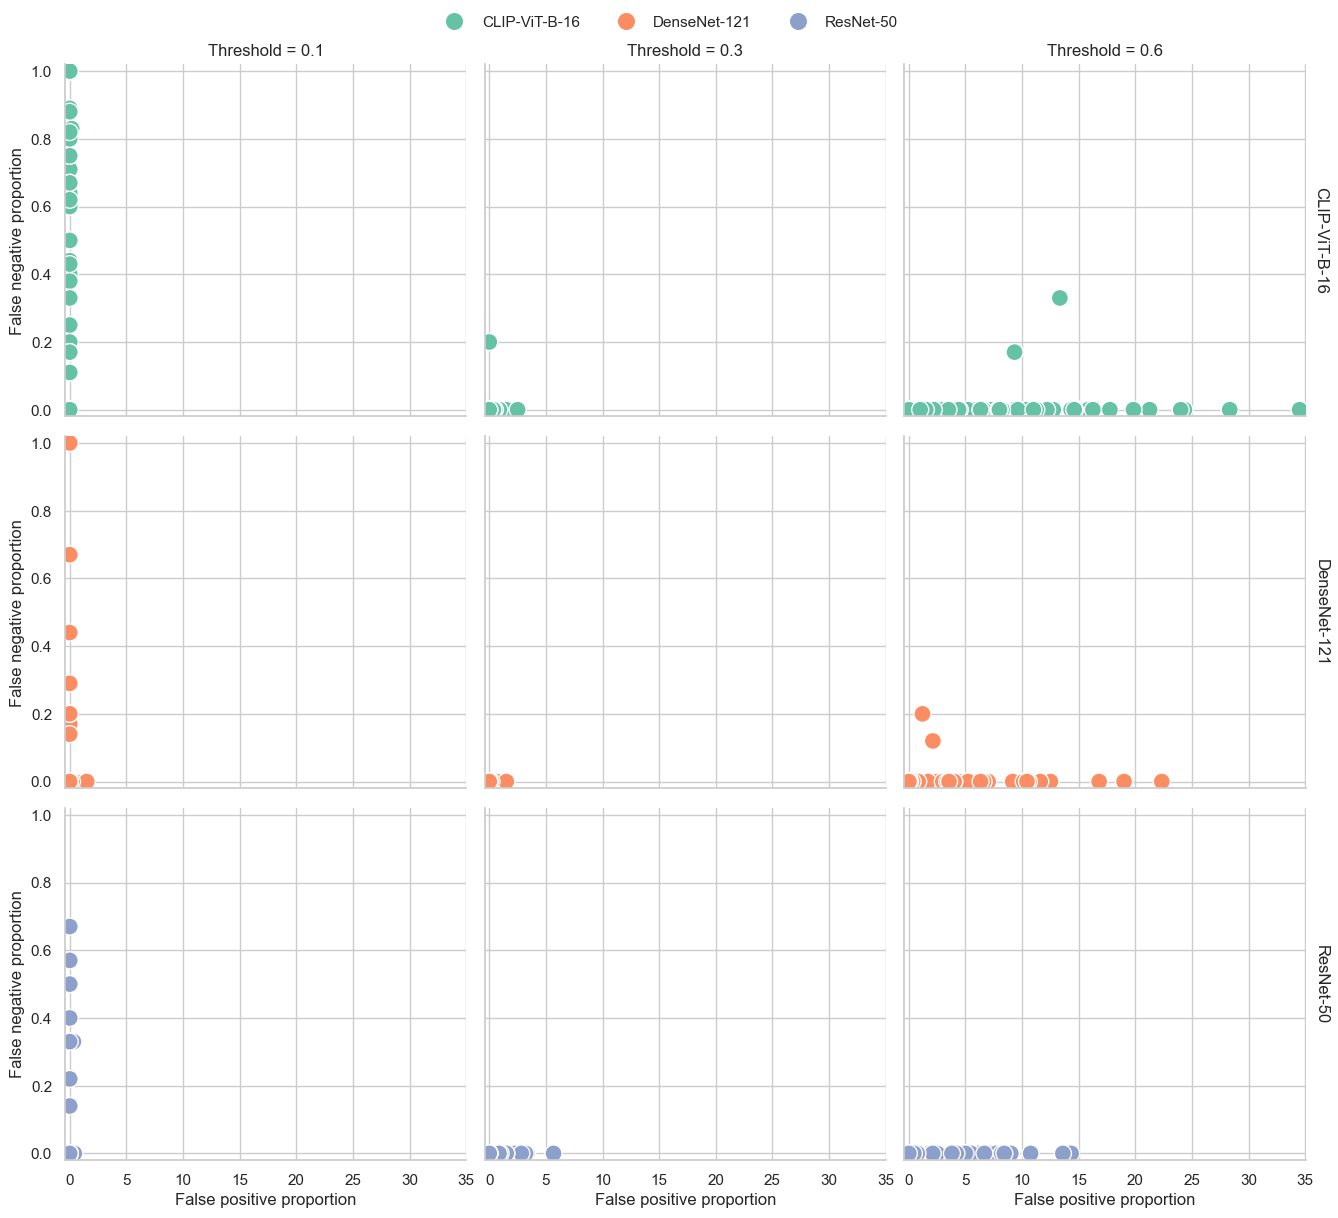

In [21]:
dfs = []
for model in models:
    for threshold in [thresholds[0],thresholds[2],thresholds[5]]:
        dfs.append(make_fpp_vs_fnp_data(threshold,model))
df_prop = pd.concat(dfs,axis=0,ignore_index=True)

sns.set_theme(style="whitegrid")
plt.figure(figsize=(12, 6))

g = sns.relplot(
    data=df_prop,
    x="False Positive Proportion",
    y="False Negative Proportion",
    row = "Model",
    col="Threshold",
    kind="scatter",
    hue="Model",
    palette="Set2",
    height=4,
    facet_kws={"margin_titles": True},
    s=150
)

g.set_axis_labels("False positive proportion", "False negative proportion")
g.set_titles(row_template="{row_name}", col_template="Threshold = {col_name:.1f}")
g.set(xlim=(-0.4, 35.02), ylim=(-0.02, 1.02))

sns.move_legend(
    g, "upper center",
    bbox_to_anchor=(0.5, 1.02),
    ncol=df_prop["Model"].nunique(),
    title=None, frameon=False,
)

plt.tight_layout()

plt.savefig('figs/fig_5.eps',bbox_inches='tight')
plt.show()

# Plot the recall@k results over different threshold values (Fig. 6)

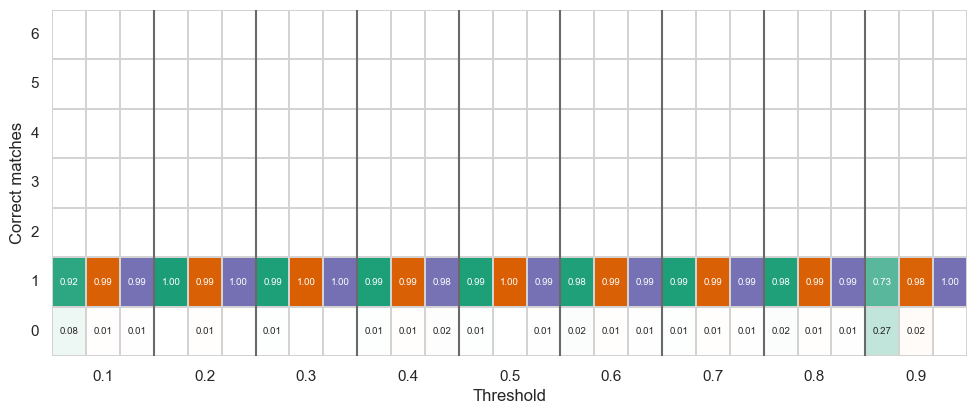

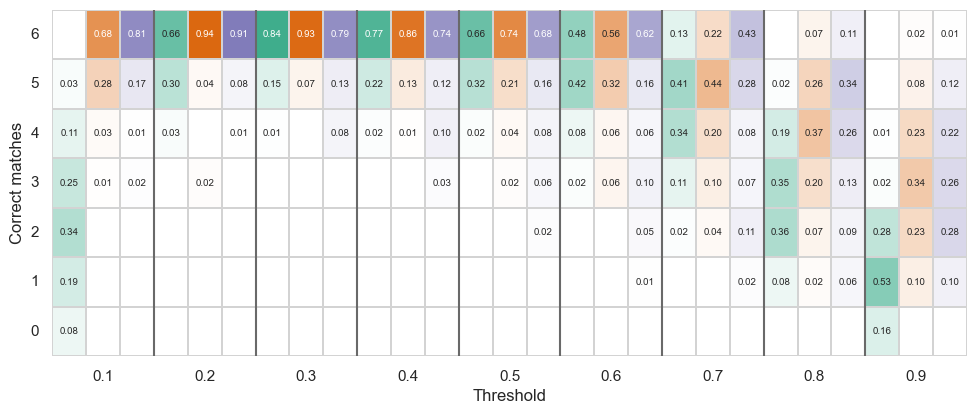

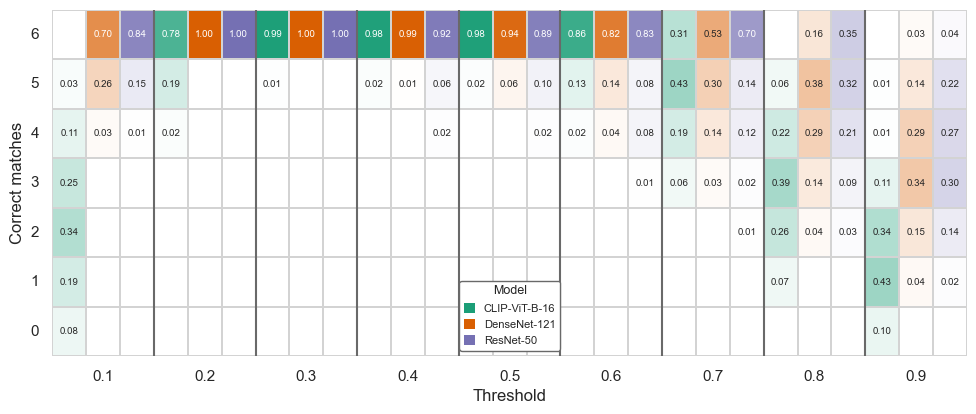

In [9]:
#  Heatmap instead of box plots.
from string import ascii_lowercase
from matplotlib.patches import Patch

sns.set_theme(style="white")
topk_values = list(range(0, 7))  # discrete Top K values 0–6
ks = sorted(df_top_k["k"].unique())

# One white-start colormap per model
base_colors = sns.color_palette("Dark2", len(models))
cmaps = {m: sns.blend_palette(["white", c], as_cmap=True) for m, c in zip(models, base_colors)}

# Interleaved columns: (t1, m1), (t1, m2), ..., (t2, m1), ...
cols = pd.MultiIndex.from_product([[round(t,1) for t in thresholds], [model_label_map[m] for m in models]], names=["Threshold", "Model"])
n_models = len(models)
col_models = cols.get_level_values("Model")

panel_w = 0.4 * len(cols) + 1
handles = [Patch(facecolor=c, edgecolor="none", label=model_label_map[m]) for m, c in zip(models, base_colors)]

for letter, k in zip(ascii_lowercase, ks):
    fig, ax = plt.subplots(figsize=(panel_w, 4.5))
    sub = df_top_k[df_top_k["k"] == k]
    # Proportion at each Top K value, per (threshold, model) column
    mat = (
        pd.crosstab(sub["Top K"], [sub["Threshold"], sub["Model"]], normalize="columns")
        .reindex(index=topk_values, columns=cols, fill_value=0)
        .iloc[::-1]  # high values at top
    )
    vals = mat.to_numpy()
    annot = np.where(vals > 0, np.vectorize("{:.2f}".format)(vals), "")

    # Overlay one heatmap per model, masking the other models' columns
    for m in models:
        mask = np.broadcast_to(col_models != model_label_map[m], vals.shape)
        sns.heatmap(
            mat, mask=mask, ax=ax, vmin=0, vmax=1, cmap=cmaps[m], cbar=False,
            annot=annot, fmt="", annot_kws={"fontsize": 7},
            linewidths=0.3, linecolor="lightgrey",
            xticklabels=False, yticklabels=True,
        )

    # Separators between threshold groups, ticks centred on each group
    for g in range(1, len(thresholds)):
        ax.axvline(g * n_models, color="dimgrey", lw=1.5)
    ax.set_xticks(np.arange(len(thresholds)) * n_models + n_models / 2)
    ax.set_xticklabels([round(t,1) for t in thresholds], rotation=0)
    ax.set_xlabel("Threshold")
    ax.set_ylabel("Correct matches")
    ax.tick_params(axis="y", rotation=0)

    # Legend: one solid square per model, boxed inside the k = 12 panel
    if k == 12:
        ax.legend(handles=handles, title="Model", loc="lower center",
                  frameon=True, framealpha=1, edgecolor="dimgrey",
                  handlelength=1, handleheight=1, fontsize=8, title_fontsize=9)

    fig.savefig(f"figs/fig6{letter}.eps", bbox_inches="tight")
    plt.show()
    plt.close(fig)

# Calculate the average downsampling percentage at different thresholds (Fig. 7)

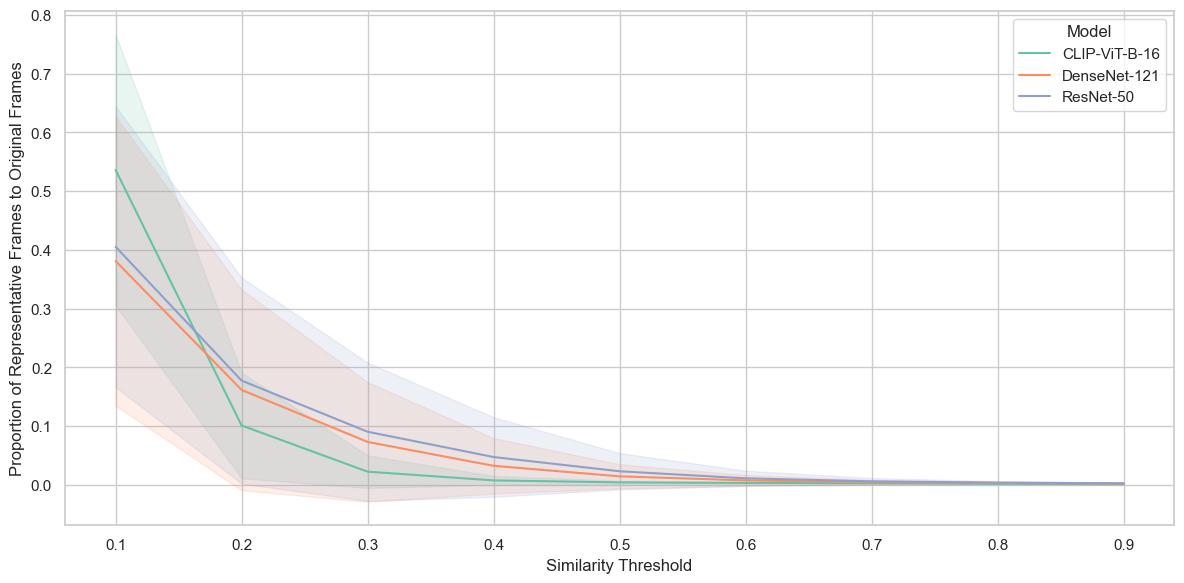

In [10]:
data_rep_frames_count = pd.read_csv('Results/Downsampled_Representative_Frames.csv')
data_rep_frames_count['Model'] = [model_label_map[m] for m in data_rep_frames_count['Model']]

sns.set_theme(style="whitegrid")
plt.figure(figsize=(12, 6))

palette = sns.color_palette("Set2", n_colors=data_rep_frames_count["Model"].nunique())
model_names = [model_label_map[m] for m in models]

color_dict = dict(zip([model_label_map[m] for m in models], palette))

ax = sns.lineplot(
    data=data_rep_frames_count,
    x="Threshold",
    y="mean",
    hue="Model",
    palette=color_dict
)

for model, group in data_rep_frames_count.groupby("Model"):
    group = group.sort_values("Threshold")

    ax.fill_between(
        group["Threshold"],
        group["mean"] - group["std"],
        group["mean"] + group["std"],
        color=color_dict[model],
        alpha=0.15
    )

    
plt.xlabel("Similarity Threshold")
plt.ylabel("Proportion of Representative Frames to Original Frames")
plt.tight_layout()
plt.savefig('figs/fig7.pdf',bbox_inches='tight')

# Number of videos matched at a given threshold - Fig S1

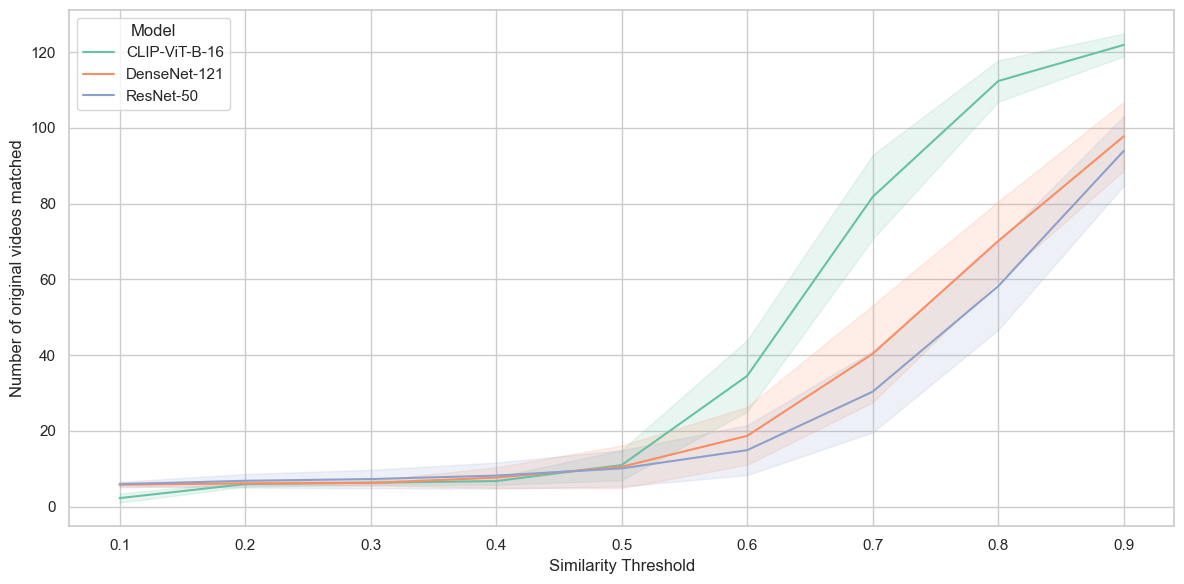

In [11]:
sns.set_theme(style="whitegrid")
plt.figure(figsize=(12, 6))

palette = sns.color_palette("Set2", n_colors=df_matches["Model"].nunique())
model_names = df_matches["Model"].unique() 

color_dict = dict(zip(model_names, palette))

ax = sns.lineplot(
    data=df_matches,
    x="Threshold",
    y="mean_matches",
    hue="Model",
    palette=color_dict
)

for model, group in df_matches.groupby("Model"):
    group = group.sort_values("Threshold")

    ax.fill_between(
        group["Threshold"],
        group["mean_matches"] - group["matches_std"],
        group["mean_matches"] + group["matches_std"],
        color=color_dict[model],
        alpha=0.15
    )
    
plt.xlabel("Similarity Threshold")
plt.ylabel("Number of original videos matched")
plt.tight_layout()

plt.savefig('figs/fig_s1.pdf',bbox_inches='tight')
plt.show()